# Figure S2e–h — HBCA clustering, markers and pathway enrichment

Replot on CPU using the bundled CSV files only. No H5AD, gene-set download or differential-expression recomputation is required.
S2e is adapted from `new_evaluations/new_scRNA/draw_fig.ipynb`; S2f-h plotting functions are extracted from
`new_evaluations/new_scRNA/downstream_figs/plot_downstream_figs.py`, preserving statistical fields and pathway-selection rules.

Follow the formal caption on page 6: e = four clustering metrics; f = LHS3; g = stripped nuclei; h = pathway enrichment.
Some e/f/g references in the body text differ from the caption. Marker bar heights are pooled-cell Welch t statistics;
stars come from donor-level one-sided Wilcoxon tests with within-population BH adjustment. Paired donors are the testing units.

**Paths:** The first code cell discovers the data root and prints every input path. If needed, edit `DATA_ROOT` or individual entries in `DATA_FILES` there, then rerun from that cell. Bundled tables and outputs always use this supplementary folder. See `README.md` for details.


In [1]:
FIGURE = 'figS2'

from pathlib import Path

# Leave both settings as None to discover this folder and the data automatically.
# DATA_ROOT may be an absolute path or a path relative to this notebook folder.
SUPP_DIR = None  # Set only if the kernel starts outside the repository/workspace.
DATA_ROOT = None  # Explicit setting takes priority over LASSOARE_DATA_ROOT.

# Relative input paths use DATA_ROOT; individual absolute paths are also supported.
DATA_FILES = {
}

import os
import runpy

# An explicit folder or VS Code's notebook location takes priority over kernel cwd.
_folder = SUPP_DIR if SUPP_DIR is not None else os.environ.get('LASSOARE_SUPPLEMENTARY_DIR')
if _folder is not None:
    _candidates = [Path(_folder).expanduser().resolve()]
else:
    _anchors = []
    if globals().get('__vsc_ipynb_file__'):
        _anchors.append(Path(__vsc_ipynb_file__).expanduser().resolve().parent)
    _anchors.append(Path.cwd())
    _candidates = []
    for _anchor in _anchors:
        for _base in (_anchor, *_anchor.parents):
            _candidates.extend([
                _base, _base / 'supplementary', _base / 'figures_res/supplementary',
                _base / 'Lasso-ARE/figures_res/supplementary',
                _base / 'git_version/Lasso-ARE/figures_res/supplementary',
            ])
SUPP_DIR = next((_p.resolve() for _p in _candidates
                 if all((_p / _name).is_file() for _name in
                        ('supplementary_paths.py', 'supplementary_utils.py', 'inputs/manifest.json'))), None)
if SUPP_DIR is None:
    raise FileNotFoundError(
        f'Cannot locate the supplementary notebook folder from {Path.cwd()}. '
        'Set SUPP_DIR in this cell to the folder containing this notebook, '
        'supplementary_paths.py, supplementary_utils.py and inputs/.'
    )

# Load this copy directly, even if another supplementary folder was used by the kernel.
_paths = runpy.run_path(str(SUPP_DIR / 'supplementary_paths.py'))
_helpers = runpy.run_path(str(SUPP_DIR / 'supplementary_utils.py'))
for _name in ('require_file', 'read_metadata', 'read_expression', 'selection_mask',
              'set_selection', 'save_figure', 'plot_embedding'):
    globals()[_name] = _helpers[_name]
REPO_ROOT = _paths['repository_root'](SUPP_DIR)
DATA_ROOT, DATA_PATHS = _paths['resolve_data_paths'](SUPP_DIR, DATA_FILES, DATA_ROOT)
INPUT_DIR = SUPP_DIR / 'inputs'
OUTPUT_DIR = SUPP_DIR / 'output' / FIGURE
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({'pdf.fonttype': 42, 'ps.fonttype': 42, 'font.family': 'DejaVu Sans'})
_paths['report_paths'](SUPP_DIR, DATA_ROOT, DATA_PATHS, OUTPUT_DIR)


Notebook folder: /home/zzj/lare/git_version/Lasso-ARE/figures_res/supplementary
Bundled inputs: /home/zzj/lare/git_version/Lasso-ARE/figures_res/supplementary/inputs
H5AD inputs: none (bundled result tables only)
Outputs: /home/zzj/lare/git_version/Lasso-ARE/figures_res/supplementary/output/figS2


In [2]:
import math
from textwrap import fill
import matplotlib as mpl
import seaborn as sns
METHOD_ORDER = ['Original', 'scVI', 'scNET', 'scFoundation', 'Lasso-ARE w/o refinement', 'Lasso-ARE + refinement']
METHOD_COLORS = {'Original': '#7F7F7F', 'scVI': '#4C78A8', 'scNET': '#72B7B2',
    'scFoundation': '#B279A2', 'Lasso-ARE w/o refinement': '#F2A541', 'Lasso-ARE + refinement': '#D1495B'}
DISPLAY_METHOD_LABELS = {'Lasso-ARE w/o refinement': 'PARE woLasso', 'Lasso-ARE + refinement': 'PARE'}
POPULATION_TITLES = {'stripped_nuclei': 'Stripped nuclei', 'LHS3': 'LHS3'}
STRIPPED_GENES = ['MALAT1', 'XIST', 'NEAT1', 'VMP1', 'CCNL1']
LHS3_GENES = ['SERPINA1', 'PIP', 'TFPI2', 'AZGP1', 'MGP']
ENRICH_METHODS = ['Lasso-ARE w/o refinement', 'Lasso-ARE + refinement']
# Upstream plotting functions use a two-argument save_figure.
save_output = _helpers['save_figure']
def save_figure(fig, stem):
    fig.tight_layout()
    save_output(fig, OUTPUT_DIR, stem)

## S2e — Clustering metrics

For each resolution, the x coordinate is the mean cluster count across the retained runs.
The y values and 95% CIs use seaborn bootstrap intervals with seed=0. These repeats are Leiden seeds, not biological replicates.
The original plot excludes woLasso to match the paper. Set `INCLUDE_WOLASSO=True` to display that configuration as well.

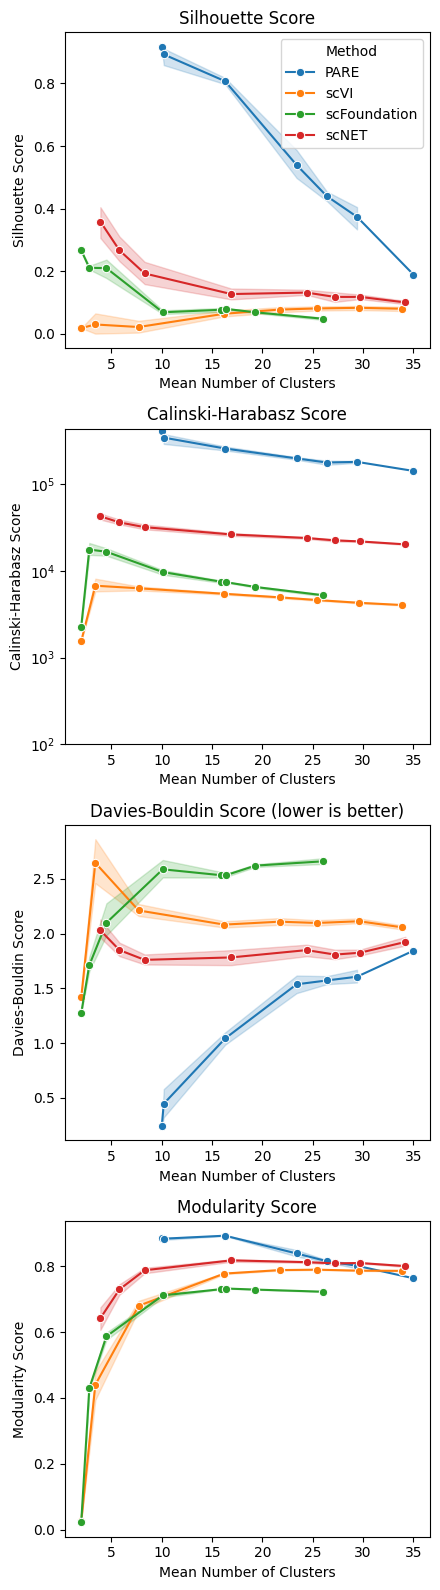

In [3]:
INCLUDE_WOLASSO = False
df = pd.read_csv(require_file(INPUT_DIR / 'figS2/clustering_results_with_bar.csv'))
df['Method'] = df['Method'].replace({'LassoARE_lasso': 'PARE', 'LassoARE_wolasso': 'PARE woLasso',
                                    'PARE_wolasso': 'PARE woLasso'})
if not INCLUDE_WOLASSO:
    df = df[df['Method'] != 'PARE woLasso'].copy()
df['Mean Number of Clusters'] = df.groupby(['Method', 'Resolution'])['Number of Clusters'].transform('mean')
metrics = ['Silhouette Score', 'Calinski-Harabasz Score', 'Davies-Bouldin Score', 'Modularity Score']
order = ['PARE'] + [m for m in df['Method'].unique() if m != 'PARE']
fig, axes = plt.subplots(4, 1, figsize=(4.5, 16))
for i, (ax, metric) in enumerate(zip(axes, metrics)):
    sns.lineplot(data=df, x='Mean Number of Clusters', y=metric, hue='Method', hue_order=order,
                 marker='o', errorbar=('ci', 95), seed=0, ax=ax, legend=(i == 0))
    ax.set_title(metric + (' (lower is better)' if metric == 'Davies-Bouldin Score' else ''))
    ax.grid(False)
    if metric == 'Calinski-Harabasz Score':
        ax.set_yscale('symlog')
        ax.set_ylim(bottom=100)
save_figure(fig, 'figS2e_clustering_metrics')

## S2f–g — Marker t statistics and paired-donor refinement advantage

In [4]:
def plot_marker_scores(
    marker_stats: pd.DataFrame,
    enrichment_stats: pd.DataFrame,
    pairwise_stats: pd.DataFrame,
    population: str,
    genes: list[str],
    stem: str,
) -> None:
    data = marker_stats[marker_stats["population"] == population]
    enrichment = enrichment_stats[enrichment_stats["population"] == population]
    pairwise = pairwise_stats[pairwise_stats["population"] == population]
    x = np.arange(len(genes), dtype=float)
    width = 0.82 / len(METHOD_ORDER)
    offsets = (np.arange(len(METHOD_ORDER)) - (len(METHOD_ORDER) - 1) / 2) * width
    fig, (ax, heat_ax) = plt.subplots(
        1,
        2,
        figsize=(17.8, 6.4),
        gridspec_kw={"width_ratios": [2.2, 1.45]},
    )
    for offset, method in zip(offsets, METHOD_ORDER):
        method_data = data[data["method"] == method].set_index("gene").reindex(genes)
        values = method_data["welch_t"].to_numpy(dtype=float)
        is_refined = method == "Lasso-ARE + refinement"
        bars = ax.bar(
            x + offset,
            values,
            width=width,
            color=METHOD_COLORS[method],
            edgecolor="#222222" if is_refined else "white",
            linewidth=1.0 if is_refined else 0.35,
            label=DISPLAY_METHOD_LABELS.get(method, method),
        )
        star_lookup = (
            enrichment[enrichment["method"] == method]
            .set_index("gene")
            .reindex(genes)["stars"]
            .fillna("NA")
        )
        for bar, star in zip(bars, star_lookup):
            height = bar.get_height()
            ax.annotate(
                star,
                (bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3 if height >= 0 else -10),
                textcoords="offset points",
                ha="center",
                va="bottom" if height >= 0 else "top",
                fontsize=10,
            )
    ax.axhline(0, color="#555555", linewidth=0.7)
    ax.set_xticks(x)
    ax.set_xticklabels(genes, fontstyle="italic", fontsize=13)
    ax.set_ylabel("Marker score (t statistic)", fontsize=15)
    ax.set_title(f"{POPULATION_TITLES[population]} marker score", fontsize=17, pad=12)
    ax.grid(axis="y", color="#E5E5E5", linewidth=0.6)
    ax.tick_params(axis="y", labelsize=13)
    ax.tick_params(axis="x", labelsize=13)
    ax.margins(y=0.14)
    ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.18), fontsize=12)

    refined = "Lasso-ARE + refinement"
    comparators = [method for method in METHOD_ORDER if method != refined]
    matrix = (
        pairwise.pivot(
            index="gene",
            columns="comparator",
            values="median_delta_donor_log2_fold_change",
        )
        .reindex(index=genes, columns=comparators)
    )
    stars = (
        pairwise.pivot(index="gene", columns="comparator", values="stars")
        .reindex(index=genes, columns=comparators)
        .fillna("NA")
    )
    values = matrix.to_numpy(dtype=float)
    max_abs = max(float(np.nanmax(np.abs(values))), 1e-6)
    image = heat_ax.imshow(
        values,
        cmap="RdBu_r",
        vmin=-max_abs,
        vmax=max_abs,
        aspect="auto",
    )
    for row in range(values.shape[0]):
        for col in range(values.shape[1]):
            value = values[row, col]
            if np.isfinite(value):
                heat_ax.text(
                    col,
                    row,
                    f"{value:+.2f}\n{stars.iloc[row, col]}",
                    ha="center",
                    va="center",
                    fontsize=11,
                )
    heat_ax.set_xticks(np.arange(len(comparators)))
    heat_ax.set_xticklabels(
        [DISPLAY_METHOD_LABELS.get(method, method) for method in comparators],
        rotation=35,
        ha="right",
        fontsize=12,
    )
    heat_ax.set_yticks(np.arange(len(genes)))
    heat_ax.set_yticklabels(genes, fontstyle="italic", fontsize=13)
    heat_ax.set_title("Refinement advantage across paired donors", fontsize=16, pad=12)
    colorbar = fig.colorbar(image, ax=heat_ax, fraction=0.046, pad=0.04)
    colorbar.set_label("Median delta donor log2FC", fontsize=13)
    colorbar.ax.tick_params(labelsize=12)
    fig.text(
        0.5,
        -0.02,
        "Stars: donor-level one-sided Wilcoxon tests, BH-adjusted within population",
        ha="center",
        fontsize=11,
    )
    save_figure(fig, stem)

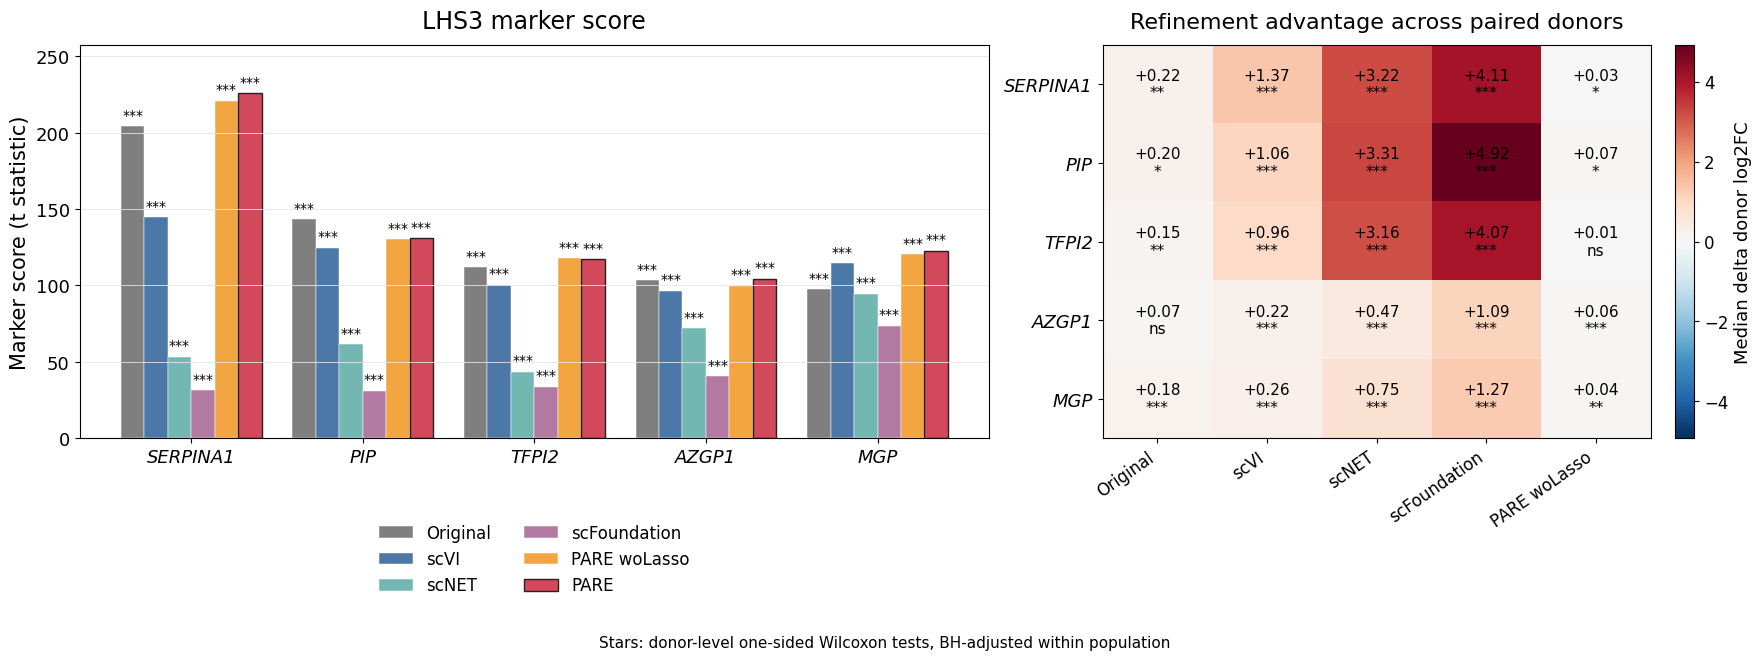

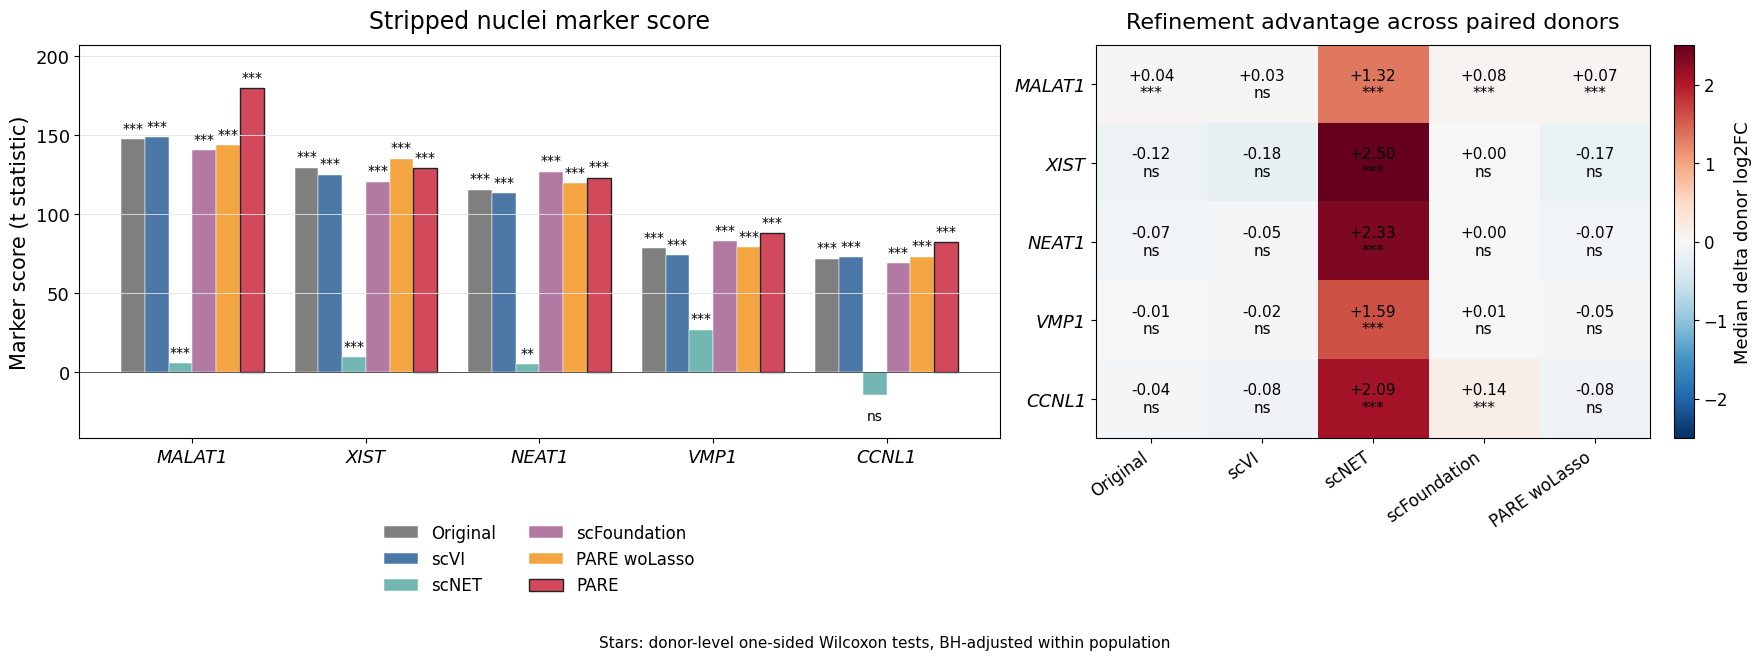

In [5]:
marker_stats = pd.read_csv(require_file(INPUT_DIR / 'figS2/marker_specificity_statistics.csv'))
donor_enrichment = pd.read_csv(require_file(INPUT_DIR / 'figS2/marker_score_donor_enrichment_significance.csv'), keep_default_na=False)
donor_pairwise = pd.read_csv(require_file(INPUT_DIR / 'figS2/marker_score_refinement_pairwise_significance.csv'), keep_default_na=False)
plot_marker_scores(marker_stats, donor_enrichment, donor_pairwise, 'LHS3', LHS3_GENES, 'figS2f_lhs3_markers')
plot_marker_scores(marker_stats, donor_enrichment, donor_pairwise, 'stripped_nuclei', STRIPPED_GENES, 'figS2g_stripped_nuclei_markers')

## S2h — Pathway enrichment

Preserve the source rule: within each population/method, sort by adjusted P and Combined Score and take the first eight terms.
Display -log10(adjusted P), capped at 50; the dashed line marks adjusted P=0.05. GO/KEGG results come from the saved table.

In [6]:
def overlap_count(value: object) -> int:
    try:
        return int(str(value).split("/", maxsplit=1)[0])
    except (ValueError, IndexError):
        return 0

def clean_term(term: str) -> str:
    if " (GO:" in term:
        term = term.split(" (GO:", maxsplit=1)[0]
    return fill(term, width=37)

def plot_pathway_enrichment(enrichment: pd.DataFrame) -> None:
    fig, axes = plt.subplots(2, 2, figsize=(12.2, 8.8))
    for row, population in enumerate(["stripped_nuclei", "LHS3"]):
        for col, method in enumerate(ENRICH_METHODS):
            ax = axes[row, col]
            subset = enrichment[
                (enrichment["method"] == method)
                & (enrichment["population"] == population)
            ].copy()
            subset["adjusted_p"] = pd.to_numeric(
                subset["Adjusted P-value"],
                errors="coerce",
            )
            subset = subset.dropna(subset=["adjusted_p"])
            subset = subset.sort_values(["adjusted_p", "Combined Score"]).head(8)
            subset = subset.sort_values("adjusted_p", ascending=False)
            if subset.empty:
                ax.text(0.5, 0.5, "No enriched terms", ha="center", va="center")
                ax.set_axis_off()
                continue
            subset["minus_log10_q"] = -np.log10(
                subset["adjusted_p"].clip(lower=np.finfo(float).tiny)
            )
            subset["plot_score"] = subset["minus_log10_q"].clip(upper=50)
            subset["overlap_count"] = subset["Overlap"].map(overlap_count)
            y = np.arange(len(subset))
            bars = ax.barh(
                y,
                subset["plot_score"],
                color=METHOD_COLORS[method],
                alpha=0.88,
                edgecolor="white",
                linewidth=0.5,
            )
            ax.set_yticks(y)
            ax.set_yticklabels([clean_term(term) for term in subset["Term"]])
            ax.axvline(-math.log10(0.05), color="#555555", linestyle="--", linewidth=0.8)
            ax.set_xlabel(r"$-\log_{10}$(adjusted P), capped at 50")
            ax.set_title(f"{POPULATION_TITLES[population]} | {DISPLAY_METHOD_LABELS.get(method, method)}")
            ax.grid(axis="x", color="#E5E5E5", linewidth=0.6)
            for bar, overlap, score in zip(
                bars,
                subset["Overlap"],
                subset["minus_log10_q"],
            ):
                label = f"{overlap}"
                if score > 50:
                    label += "  >50"
                ax.text(
                    bar.get_width() + 0.35,
                    bar.get_y() + bar.get_height() / 2,
                    label,
                    va="center",
                    fontsize=11,
                )
    save_figure(fig, "figS2h_pathway_enrichment")

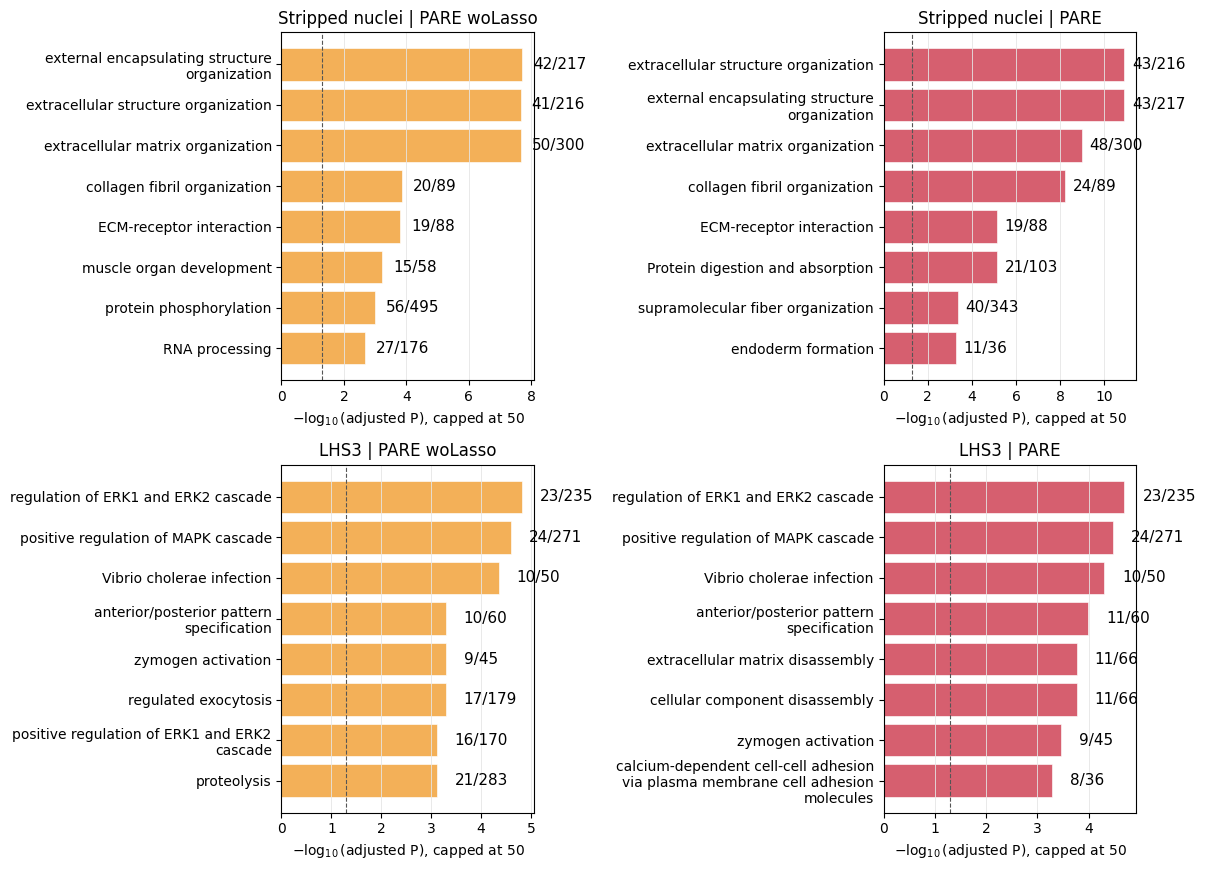

In [7]:
enrichment = pd.read_csv(require_file(INPUT_DIR / 'figS2/pathway_enrichment_results.csv'))
plot_pathway_enrichment(enrichment)